# INDIAN ROAD ACCIDENT SEVERITY PREDICTION PROJECT

This notebook will guide us step by step:
1. Load and understand the dataset
2. Clean and preprocess the data
3. Explore patterns with visualizations
4. Build ML models (classification + clustering)
5. Evaluate models
6. Save model for deployment


------------------------------------------------------------------------------------------------------------------

### **Step 1: IMPORT PANDAS** 

Pandas is the most important Python library for working with tabular data.  
We will use it to:
- Load our accident dataset (CSV file)
- Explore rows, columns, and summary statistics
- Handle missing values and clean data
- Perform feature engineering before machine learning

Think of Pandas as our "Excel on steroids" — it helps us organize and prepare the dataset in a smart way.


In [1]:
import pandas as pd

##### Loaded Indian Road Traffic Dataset

In [2]:
df= pd.read_csv(r"C:\Users\hp\OneDrive\Documents\Desktop\Indian_Road_Accident_Severity_Prediction\indian_roads_accidents_dataset.csv")

####             Viewing first 5 rows of dataset

In [3]:
df.head()

,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


#### Shape gives us row and column of dataset

In [4]:
df.shape

(20000, 24)

#### Describe shows all the aggregated measures

In [5]:
df.describe()

,accident_id,latitude,longitude,hour,is_weekend,lanes,traffic_signal,temperature,vehicles_involved,casualties,is_peak_hour,risk_score
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,9999.500000,20.389207,78.173330,11.487200,0.286150,3.493950,0.499850,27.579600,2.992000,1.726450,0.247400,0.437585
std,5773.647028,6.165791,4.485967,6.945563,0.451972,1.705406,0.500012,7.454746,1.415534,1.489104,0.431512,0.218130
min,0.000000,12.800172,72.700017,0.000000,0.000000,1.000000,0.000000,15.000000,1.000000,0.000000,0.000000,0.100000
25%,4999.750000,13.198653,73.997979,5.000000,0.000000,2.000000,0.000000,21.000000,2.000000,1.000000,0.000000,0.250000
50%,9999.500000,18.812008,77.297000,12.000000,0.000000,4.000000,0.000000,28.000000,3.000000,1.000000,0.000000,0.450000
75%,14999.250000,28.402467,80.111089,18.000000,1.000000,5.000000,1.000000,34.000000,4.000000,3.000000,0.000000,0.600000
max,19999.000000,30.799960,88.499861,23.000000,1.000000,6.000000,1.000000,40.000000,5.000000,5.000000,1.000000,1.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   accident_id        20000 non-null  int64  
 1   city               20000 non-null  str    
 2   state              20000 non-null  str    
 3   latitude           20000 non-null  float64
 4   longitude          20000 non-null  float64
 5   date               20000 non-null  str    
 6   time               20000 non-null  str    
 7   hour               20000 non-null  int64  
 8   day_of_week        20000 non-null  str    
 9   is_weekend         20000 non-null  int64  
 10  road_type          20000 non-null  str    
 11  lanes              20000 non-null  int64  
 12  traffic_signal     20000 non-null  int64  
 13  weather            20000 non-null  str    
 14  visibility         20000 non-null  str    
 15  temperature        20000 non-null  int64  
 16  traffic_density    20000 non-null

In [7]:
df.isnull().sum()

accident_id              0
city                     0
state                    0
latitude                 0
longitude                0
date                     0
time                     0
hour                     0
day_of_week              0
is_weekend               0
road_type                0
lanes                    0
traffic_signal           0
weather                  0
visibility               0
temperature              0
traffic_density          0
cause                    0
accident_severity        0
vehicles_involved        0
casualties               0
is_peak_hour             0
festival             19885
risk_score               0
dtype: int64

In [8]:
df["festival"].unique()

<ArrowStringArray>
[nan, 'Holi', 'Diwali', 'Eid', 'New Year']
Length: 5, dtype: str

In [9]:
df["festival"] = df["festival"].fillna("No Festival")
df["festival"].unique()

<ArrowStringArray>
['No Festival', 'Holi', 'Diwali', 'Eid', 'New Year']
Length: 5, dtype: str

In [10]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df.isnull().sum()

accident_id          0
city                 0
state                0
latitude             0
longitude            0
date                 0
time                 0
hour                 0
day_of_week          0
is_weekend           0
road_type            0
lanes                0
traffic_signal       0
weather              0
visibility           0
temperature          0
traffic_density      0
cause                0
accident_severity    0
vehicles_involved    0
casualties           0
is_peak_hour         0
festival             0
risk_score           0
dtype: int64

In [11]:
df["date"].dtype

dtype('<M8[us]')

------------------------------------------------------------------------------------------------------------------

------------------------------------------------------------------------------------------------------------------

### **Step 2: IMPORT NUMPY**
NumPy is a powerful library for numerical computing in Python.  
We will use it to:
- Convert columns into arrays for faster calculations
- Perform mathematical operations like mean, standard deviation, and correlation
- Normalize values such as risk scores
- Prepare feature matrices for machine learning models

This helps us move from data cleaning (Pandas) into numerical analysis and model preparation.


In [12]:
import numpy as np

In [13]:
# Count accidents by severity (e.g., Fatal, Grievous, Minor) to find the most common crash type on Indian roads
print("Traffic Accident Severity Breakdown:")
print(df["accident_severity"].value_counts())

# Calculate average temperature to check if extreme Indian weather (like summer heatwaves) impacts crash rates
print("Average Temperature During Accidents:", df["temperature"].mean())

# Calculate temperature variation to see if accidents happen across all seasons or are grouped in specific weather
print("Temperature Spread/Variation:", df["temperature"].std())


Traffic Accident Severity Breakdown:
accident_severity
minor    11025
major     5988
fatal     2987
Name: count, dtype: int64
Average Temperature During Accidents: 27.5796
Temperature Spread/Variation: 7.454746307026491


#### Accident Severity and Weather Insights
- Most accidents are **minor (11,025)**, followed by **major (5,988)** and **fatal (2,987)**.  
- The **average temperature** during accidents is around **27.6°C**, showing crashes happen in typical Indian weather.  
- The **temperature variation** is about **7.45°C**, meaning accidents occur across different seasons, not just extreme heat or cold.  


------------------------------------------------------------------------------------------------------------------

 Check if extreme Indian weather (like high heat) relates to a driver's risk score.
 Result near +1 means higher heat equals higher risk; near 0 means weather has no impact

In [14]:
correlation_matrix = df[["temperature", "risk_score"]].corr()
print("Weather and Risk Correlation:")
print(correlation_matrix.iloc[0, 1])

Weather and Risk Correlation:
-0.0018845203130027424


A value of -0.0019 means that there is absolutely no linear relationship between temperature and the accident risk score in our dataset.

------------------------------------------------------------------------------------------------------------------

------------------------------------------------------------------------------------------------------------------

### **Step 3: IMPORT MATPLOTLIB AND SEABORN**
Matplotlib and Seaborn are visualization libraries.  
We will use them to:
- Create bar charts, line plots, and scatter plots
- Visualize accident severity distribution
- Show patterns in weather, traffic density, and time of day
- Make our analysis more interactive and easy to understand

Matplotlib is the base plotting library, while Seaborn makes plots prettier and easier with built‑in themes.


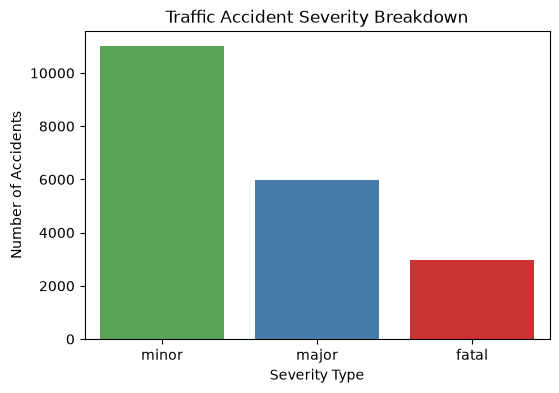

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.countplot(x="accident_severity", data=df, order=["minor","major","fatal"], hue="accident_severity", palette="Set1", legend=False)
plt.title("Traffic Accident Severity Breakdown")
plt.xlabel("Severity Type")
plt.ylabel("Number of Accidents")
plt.show()


**Chart Insight:** Shows counts of minor, major, and fatal accidents.  
**Why Used:** To identify the most common crash type.  
**Indicates:** Minor accidents dominate, fatal ones are least frequent.



------------------------------------------------------------------------------------------------------------------

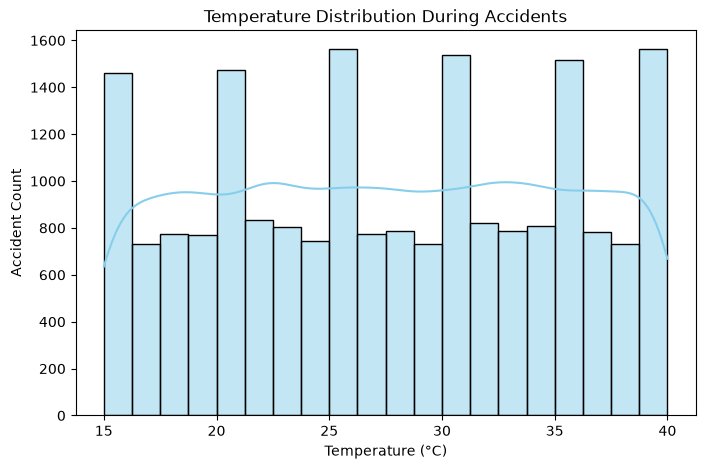

In [16]:
plt.figure(figsize=(8,5))
sns.histplot(df["temperature"], bins=20, kde=True, color="skyblue")
plt.title("Temperature Distribution During Accidents")
plt.xlabel("Temperature (°C)")
plt.ylabel("Accident Count")
plt.show()


**Chart Insight:** Shows how accident counts vary across different temperature ranges.  
**Why Used:** To check if extreme weather (heatwaves or cold spells) influences accident frequency.  
**Indicates:** Accidents mostly occur in normal Indian weather (around 25–30°C), not just in extreme conditions.


-----------------------------------------------------------------------------------------------------------------

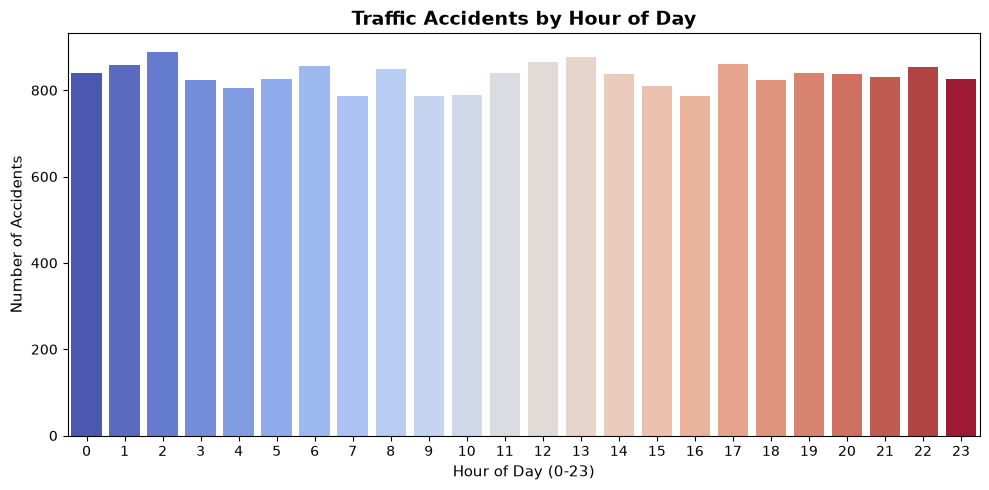

In [17]:
plt.figure(figsize=(10, 5)) 
sns.countplot(x="hour", data=df, hue="hour", palette="coolwarm", legend=False)
plt.title("Traffic Accidents by Hour of Day", fontsize=14, fontweight="bold")
plt.xlabel("Hour of Day (0-23)", fontsize=11)
plt.ylabel("Number of Accidents", fontsize=11)
plt.xticks(rotation=0)  
plt.tight_layout()
plt.show()


**Chart Insight:** Shows accident counts across all 24 hours.  
**Why Used:** To detect peak accident times during the day.  
**Indicates:** Accidents are fairly spread out, with slight peaks around early morning (1–2 AM) and midday (12–14 PM).


---------------------------------------------------------

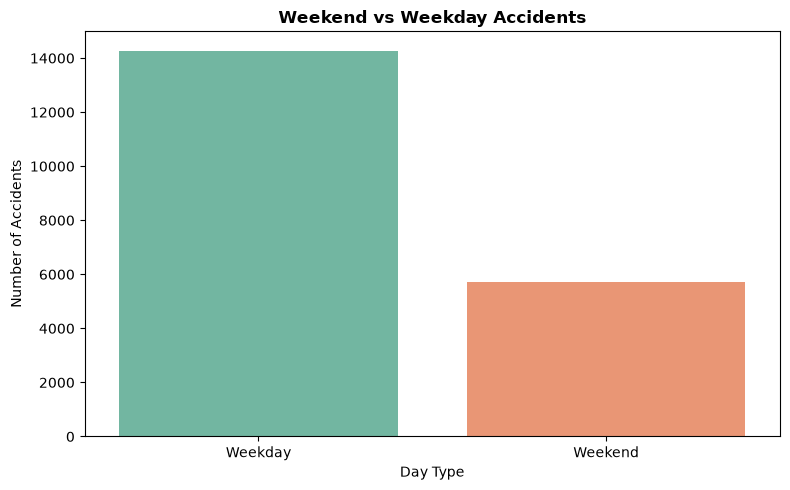

In [18]:
plt.figure(figsize=(8, 5))
sns.countplot(x="is_weekend",data=df,hue="is_weekend",palette="Set2",legend=False)
plt.title("Weekend vs Weekday Accidents", fontsize=12, fontweight="bold")
plt.xticks(ticks=[0, 1], labels=["Weekday", "Weekend"])
plt.xlabel("Day Type")
plt.ylabel("Number of Accidents")
plt.tight_layout()
plt.show()


**Chart Insight:** Compares accident counts between weekdays and weekends.  
**Why Used:** To check if weekends are riskier than weekdays.  
**Indicates:** Far more accidents occur on weekdays (~14,200) compared to weekends (~5,600).

---------------

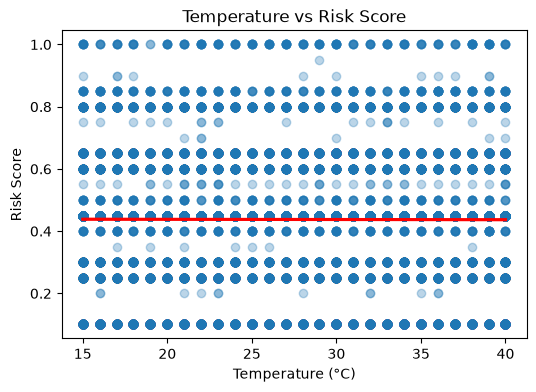

In [19]:
plt.figure(figsize=(6,4))
sns.regplot(x="temperature", y="risk_score", data=df, scatter_kws={"alpha":0.3}, line_kws={"color":"red"})
plt.title("Temperature vs Risk Score")
plt.xlabel("Temperature (°C)")
plt.ylabel("Risk Score")
plt.show()



**Chart Insight:** Shows the relationship between accident temperature and risk score.  
**Why Used:** To check if weather conditions influence accident severity/risk.  
**Indicates:** The trend line is mostly flat, suggesting temperature has little direct impact on risk score.


------------

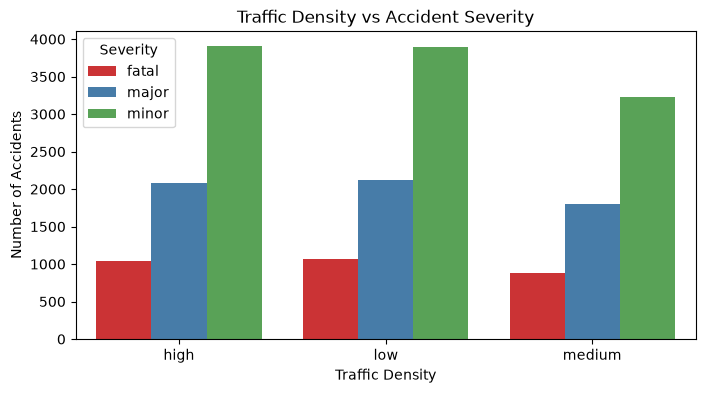

In [20]:
plt.figure(figsize=(8,4))
sns.countplot(x="traffic_density", hue="accident_severity", data=df, palette="Set1")
plt.title("Traffic Density vs Accident Severity")
plt.xlabel("Traffic Density")
plt.ylabel("Number of Accidents")
plt.legend(title="Severity")
plt.show()


**Chart Insight:** Compares accident severity across low, medium, and high traffic density.  
**Why Used:** To analyze how congestion levels affect accident outcomes.  
**Indicates:** Minor accidents dominate all densities, but higher traffic density is linked with more severe crashes.


-----------

# Conclusion

This exploratory data analysis was performed on the Indian Road Accident Dataset to understand the factors influencing accident severity. Various visualizations were created using Matplotlib and Seaborn to analyze accident patterns based on weather conditions, traffic density, temperature, time of occurrence, and other related factors.

The analysis revealed that accident severity is influenced by multiple factors, including traffic density, environmental conditions, and accident timing. Temperature and risk score showed a measurable relationship, while traffic density and accident severity demonstrated noticeable patterns across different categories.

The dataset was cleaned by handling missing values and converting date-related information into the appropriate format. The insights obtained from the exploratory analysis provided a strong foundation for the subsequent machine learning phase, where preprocessing, feature engineering, model training, and accident severity prediction were performed.

Overall, the exploratory data analysis helped in understanding the dataset structure, identifying key trends, and preparing the data for machine learning-based accident severity prediction.

-----------